# Notebook 2b: Semantic Embeddings for Ticket Classification

Notebook 02 found that TF-IDF models **match words, not meaning**. For example, "My account was locked after multiple failed
**login** attempts" went to security_concern only because the word "login" appeared in a security sentence.

Here we replace TF-IDF with **sentence embeddings**: pre-trained neural models that turn a sentence into a vector so that
sentences with similar *meaning* get similar vectors, even when they share no words.

**Plan**
1. Use the same data, the same split by message and the same grouped 5-fold CV as notebook 02, so the scores can be compared directly
2. Build four text representations: TF-IDF (the notebook 02 baseline) and three sentence-embedding models
3. Train the same set of classifiers on each one: Logistic Regression, Linear SVM, k-Nearest Neighbours, Random Forest (+ Naive Bayes for TF-IDF)
4. Compare every combination on accuracy, precision, recall, F1 and ROC-AUC
5. Look closely at the best combination: per-class scores, confusion matrix, the hard sentences from notebook 02 and the confidence rule

**Requirements:** `pip install sentence-transformers`. The first run downloads the three models (about 0.6 GB in total) from Hugging Face.

In [1]:
import os
os.environ.update(HF_HUB_DISABLE_PROGRESS_BARS="1", TRANSFORMERS_VERBOSITY="error", TQDM_DISABLE="1")
import sys
import json
import time
import logging
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
logging.disable(logging.WARNING)   # hide torch / Hugging Face start-up notices
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)
from sentence_transformers import SentenceTransformer

sys.path.append("..")
from src import config

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 250)

TEXT, TARGET, SEED = config.TEXT, config.TARGET, config.SEED
FIG = config.FIGURES

## 1. Same data, same splits as notebook 02

We rebuild exactly the same message-level train/test split and the same grouped CV folds, so every number here
can be put next to notebook 02.

In [2]:
tickets = pd.read_csv(config.PROCESSED / "tickets_clean.csv")
X, y = tickets[TEXT], tickets[TARGET]
classes = sorted(y.unique())

# the 96 unique messages, in the same order notebook 02 uses for its split
messages = tickets[[TEXT, TARGET]].drop_duplicates().reset_index(drop=True)
msg_id = X.map({s: i for i, s in enumerate(messages[TEXT])}).values   # which message each ticket uses
msg_label = messages[TARGET].values

train_msgs, test_msgs = train_test_split(messages, test_size=0.2, random_state=SEED, stratify=messages[TARGET])
holdout_train = X.isin(train_msgs[TEXT]).values                       # True for training tickets

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y, groups=X))

print(f"Tickets: {len(tickets):,} | unique messages: {len(messages)} | classes: {len(classes)}")
print(f"Holdout: {holdout_train.sum():,} train tickets ({len(train_msgs)} messages), "
      f"{(~holdout_train).sum():,} test tickets ({len(test_msgs)} messages)")

Tickets: 20,000 | unique messages: 96 | classes: 8
Holdout: 15,477 train tickets (76 messages), 4,523 test tickets (20 messages)


## 2. Four ways to turn text into numbers

| Representation | Type | Size | Idea |
|---|---|---|---|
| **TF-IDF** (notebook 02) | word counts | ~400 | One number per word / word pair. Two sentences are similar only if they share words. |
| **all-MiniLM-L6-v2** | sentence embedding | 384 | Small, fast transformer trained on 1 billion sentence pairs to put paraphrases close together. |
| **all-mpnet-base-v2** | sentence embedding | 768 | Larger model from the same family; usually better quality than MiniLM. |
| **BAAI/bge-base-en-v1.5** | sentence embedding | 768 | Newer model trained for retrieval and similarity; among the strongest models of its size. |

The embedding models are used as they are (no fine-tuning). Each vector is scaled to length 1, so the dot product of two vectors is their cosine similarity.
Only the 96 unique messages need to be encoded; every ticket then reuses its message's vector.

In [3]:
EMBEDDERS = {
    "MiniLM": "sentence-transformers/all-MiniLM-L6-v2",
    "MPNet": "sentence-transformers/all-mpnet-base-v2",
    "BGE": "BAAI/bge-base-en-v1.5",
}
REPS = ["TF-IDF"] + list(EMBEDDERS)

embeddings = {}
for short, name in EMBEDDERS.items():
    start = time.time()
    embeddings[short] = SentenceTransformer(name).encode(messages[TEXT].tolist(), normalize_embeddings=True, show_progress_bar=False)
    print(f"{short:7s} {name:40s} -> {embeddings[short].shape}  ({time.time() - start:.1f}s)")

def features(rep, train_mask):
    """Feature matrix for the 96 messages. TF-IDF is fitted on the training tickets only; embeddings need no fitting."""
    if rep == "TF-IDF":
        vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(X[train_mask])
        return vec.transform(messages[TEXT])
    return embeddings[rep]

MiniLM  sentence-transformers/all-MiniLM-L6-v2   -> (96, 384)  (4.0s)


MPNet   sentence-transformers/all-mpnet-base-v2  -> (96, 768)  (2.2s)


BGE     BAAI/bge-base-en-v1.5                    -> (96, 768)  (2.0s)


### Do the embeddings capture meaning? A quick check

Below are the two sentences notebook 02 got wrong. For each one we list its closest **training** sentences, once with TF-IDF and once with BGE.

In [4]:
def nearest_training(sentence, rep, k=3):
    F = features(rep, holdout_train)
    F = F.toarray() if hasattr(F, "toarray") else F
    F = F / np.linalg.norm(F, axis=1, keepdims=True).clip(1e-12)
    i = messages.index[messages[TEXT] == sentence][0]
    train_ids = np.where(messages[TEXT].isin(train_msgs[TEXT]))[0]
    sims = F[train_ids] @ F[i]
    top = train_ids[np.argsort(-sims)[:k]]
    return pd.DataFrame({"representation": rep, "similarity": np.sort(sims)[::-1][:k],
                         "label": msg_label[top], "training sentence": messages.loc[top, TEXT].values})

for sentence in ["My account was locked after multiple failed login attempts.",
                 "I need help but I'm not sure which category this fits in."]:
    true = msg_label[messages[TEXT] == sentence][0]
    print(f"\n>>> {sentence}   (true label: {true})")
    display(pd.concat([nearest_training(sentence, "TF-IDF"), nearest_training(sentence, "BGE")], ignore_index=True))


>>> My account was locked after multiple failed login attempts.   (true label: account_access)


,representation,similarity,label,training sentence
0,TF-IDF,0.403,security_concern,I noticed a suspicious login on my account.
1,TF-IDF,0.292,other,I have a general question about my account.
2,TF-IDF,0.184,billing_problem,I was charged twice for my subscription this month.
3,BGE,0.787,account_access,I cannot log in; the system says my password is incorrect.
4,BGE,0.728,bug,I am seeing an error message when I click on login auth.
5,BGE,0.708,bug,The page keeps crashing whenever I try to open the login auth section.



>>> I need help but I'm not sure which category this fits in.   (true label: other)


,representation,similarity,label,training sentence
0,TF-IDF,0.323,how_to,I need help setting up notifications for my team.
1,TF-IDF,0.313,how_to,I need help setting up data export for my team.
2,TF-IDF,0.313,how_to,I need help setting up login auth for my team.
3,BGE,0.674,other,I have a general question about my account.
4,BGE,0.621,other,"Something seems off, can you please check my workspace?"
5,BGE,0.584,how_to,I need help setting up mobile app for my team.


TF-IDF finds training sentences that **share words** ("login", "account", "I need help"), even when they mean something different. BGE finds sentences with the **same meaning**:

- The lockout sentence's closest neighbour is "I cannot log in; the system says my password is incorrect" (account_access, similarity 0.79). TF-IDF's closest is the *suspicious login* sentence (security_concern).
- The "not sure which category" sentence lands next to two other `other` sentences ("I have a general question…", "Something seems off…"). TF-IDF puts it next to three how_to sentences that start with "I need help".

This is the notebook 02 failure, fixed at the level of the representation.

## 3. Training setup

Every ticket that uses the same message has the same text and the same label. So instead of training on 15,000+ duplicate rows, we train on the
**unique training messages, weighted by how many tickets use them**. For Logistic Regression, SVM, Naive Bayes and Random Forest this gives the
same model as training on every ticket, and it is about 100 times faster. (Check: the TF-IDF models below reproduce notebook 02's CV score exactly.)
k-Nearest Neighbours is the exception: it simply looks up the 3 most similar training *messages*.

All scores are still computed **per ticket**, exactly as in notebook 02.

| Classifier | Idea in one line |
|---|---|
| Logistic Regression | One weight per feature per category, turned into probabilities |
| Linear SVM | Widest-margin linear boundary (scores turned into probabilities with a softmax for ROC-AUC) |
| k-Nearest Neighbours | Vote of the 3 most similar training messages (cosine similarity, closer counts more) |
| Random Forest | 300 decision trees voting; can learn non-linear rules |
| Naive Bayes | Word-count model; only used with TF-IDF, because it needs non-negative features |

In [5]:
CLASSIFIERS = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=3000, C=1.0),
    "Linear SVM": lambda: LinearSVC(C=1.0, max_iter=20000),
    "kNN (k=3)": lambda: KNeighborsClassifier(n_neighbors=3, metric="cosine", weights="distance"),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Naive Bayes": lambda: MultinomialNB(alpha=0.5),
}
COMBOS = [(r, c) for r in REPS for c in CLASSIFIERS if not (c == "Naive Bayes" and r != "TF-IDF")]

def softmax(s):
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def fit_predict(rep, clf_name, train_mask):
    """Train on the messages of the training tickets; return class probabilities for every message (rows) x class (cols)."""
    F = features(rep, train_mask)
    train_ids, weights = np.unique(msg_id[train_mask], return_counts=True)
    model = CLASSIFIERS[clf_name]()
    if clf_name.startswith("kNN"):
        model.fit(F[train_ids], msg_label[train_ids])
    else:
        model.fit(F[train_ids], msg_label[train_ids], sample_weight=weights)
    scores = model.predict_proba(F) if hasattr(model, "predict_proba") else softmax(model.decision_function(F))
    out = np.zeros((len(messages), len(classes)))                    # put columns in the global class order
    out[:, [classes.index(c) for c in model.classes_]] = scores
    return out

def scores_for(y_true, proba):
    pred = np.array(classes)[proba.argmax(axis=1)]
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision_macro": precision_score(y_true, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, pred, average="weighted", zero_division=0),
        "roc_auc_macro": roc_auc_score(label_binarize(y_true, classes=classes), proba, average="macro"),
    }

## 4. Results on the holdout test set (20 unseen messages)

In [6]:
test_mask = ~holdout_train
rows = []
baseline = DummyClassifier(strategy="most_frequent").fit(X[holdout_train], y[holdout_train])
rows.append({"representation": "-", "classifier": "Majority baseline",
             **scores_for(y[test_mask], label_binarize(baseline.predict(X[test_mask]), classes=classes).astype(float))})
for rep, clf in COMBOS:
    proba = fit_predict(rep, clf, holdout_train)[msg_id[test_mask]]
    rows.append({"representation": rep, "classifier": clf, **scores_for(y[test_mask], proba)})

holdout = pd.DataFrame(rows)
holdout.sort_values("f1_macro", ascending=False).reset_index(drop=True)

,representation,classifier,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_macro
0,BGE,Random Forest,1.000,1.000,1.000,1.000,1.000,1.000
1,BGE,Linear SVM,1.000,1.000,1.000,1.000,1.000,1.000
2,BGE,Logistic Regression,1.000,1.000,1.000,1.000,1.000,1.000
3,MPNet,Logistic Regression,0.821,0.797,0.875,0.819,0.771,1.000
4,MiniLM,Logistic Regression,0.821,0.797,0.875,0.819,0.771,0.971
5,MiniLM,Linear SVM,0.821,0.797,0.875,0.819,0.771,0.943
6,MPNet,Linear SVM,0.821,0.797,0.875,0.819,0.771,1.000
7,MPNet,kNN (k=3),0.923,0.809,0.842,0.818,0.902,0.941
8,BGE,kNN (k=3),0.777,0.767,0.836,0.777,0.726,0.998
9,MiniLM,kNN (k=3),0.747,0.607,0.709,0.638,0.688,0.876


On the 20 holdout messages, **BGE with Logistic Regression, SVM or Random Forest gets every ticket right** (macro F1 1.00). MiniLM and MPNet reach 0.82, and every TF-IDF model stays at 0.61 or lower. The TF-IDF + LR score matches notebook 02 exactly (0.611), which confirms the setup is the same.

But 20 messages is a tiny test, and one sentence moves macro F1 by 0.1 or more. The grouped cross-validation below is the result to trust.

## 5. Grouped 5-fold cross-validation (the main result)

The holdout test has only 20 messages, so one sentence can move macro F1 a lot. Grouped CV tests every one of the 96 messages exactly once,
always with a model that never saw it. We report:
- the **mean and spread of macro F1 across the 5 folds** (same as `cv_scores.csv` from notebook 02), and
- scores on the **out-of-fold predictions for all 20,000 tickets** (same as `metrics.json` from notebook 02).

In [7]:
cv_rows, oof = [], {}
for rep, clf in COMBOS:
    fold_f1, fold_acc, fold_wf1 = [], [], []
    oof_proba = np.zeros((len(X), len(classes)))
    for train_idx, test_idx in folds:
        mask = np.zeros(len(X), bool); mask[train_idx] = True
        proba = fit_predict(rep, clf, mask)[msg_id[test_idx]]
        oof_proba[test_idx] = proba
        pred = np.array(classes)[proba.argmax(axis=1)]
        fold_f1.append(f1_score(y.iloc[test_idx], pred, average="macro"))
        fold_wf1.append(f1_score(y.iloc[test_idx], pred, average="weighted"))
        fold_acc.append(accuracy_score(y.iloc[test_idx], pred))
    oof[(rep, clf)] = oof_proba
    o = scores_for(y, oof_proba)
    cv_rows.append({"representation": rep, "classifier": clf,
                    "f1_macro_mean": np.mean(fold_f1), "f1_macro_std": np.std(fold_f1),
                    "f1_weighted_mean": np.mean(fold_wf1), "accuracy_mean": np.mean(fold_acc),
                    "oof_f1_macro": o["f1_macro"], "oof_precision_macro": o["precision_macro"],
                    "oof_recall_macro": o["recall_macro"], "oof_roc_auc_macro": o["roc_auc_macro"]})

cv_scores = pd.DataFrame(cv_rows)
cv_scores.sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)

,representation,classifier,f1_macro_mean,f1_macro_std,f1_weighted_mean,accuracy_mean,oof_f1_macro,oof_precision_macro,oof_recall_macro,oof_roc_auc_macro
0,BGE,Linear SVM,0.822,0.092,0.789,0.832,0.816,0.864,0.833,0.998
1,BGE,Logistic Regression,0.813,0.099,0.802,0.832,0.816,0.864,0.833,0.994
2,BGE,kNN (k=3),0.795,0.074,0.767,0.807,0.795,0.849,0.806,0.969
3,MPNet,Logistic Regression,0.789,0.119,0.742,0.797,0.753,0.763,0.792,0.992
4,MPNet,Linear SVM,0.789,0.119,0.742,0.797,0.745,0.744,0.792,0.988
5,MiniLM,Logistic Regression,0.708,0.161,0.656,0.709,0.660,0.651,0.709,0.956
6,MiniLM,Linear SVM,0.695,0.173,0.644,0.709,0.649,0.672,0.709,0.956
7,BGE,Random Forest,0.693,0.184,0.651,0.708,0.649,0.626,0.709,0.970
8,MiniLM,Random Forest,0.599,0.072,0.563,0.619,0.591,0.643,0.620,0.904
9,MPNet,kNN (k=3),0.591,0.094,0.589,0.630,0.613,0.663,0.636,0.876


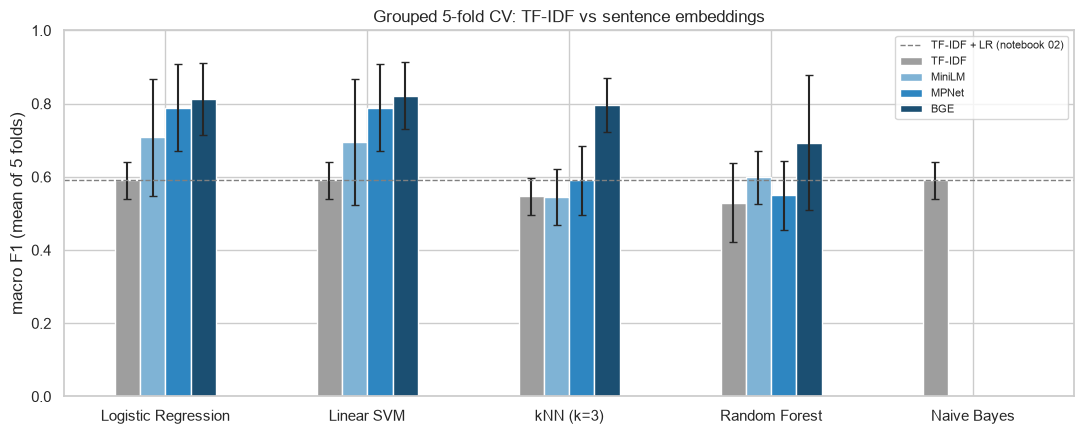

In [8]:
pivot = cv_scores.pivot(index="classifier", columns="representation", values="f1_macro_mean")[REPS]
err = cv_scores.pivot(index="classifier", columns="representation", values="f1_macro_std")[REPS]
order = ["Logistic Regression", "Linear SVM", "kNN (k=3)", "Random Forest", "Naive Bayes"]
ax = pivot.loc[order].plot.bar(yerr=err.loc[order], capsize=3, figsize=(11, 4.5), rot=0,
                               color=["#9e9e9e", "#7fb3d5", "#2e86c1", "#1b4f72"])
ax.axhline(cv_scores.query("representation == 'TF-IDF' and classifier == 'Logistic Regression'")["f1_macro_mean"].item(),
           color="grey", ls="--", lw=1, label="TF-IDF + LR (notebook 02)")
ax.set_ylim(0, 1); ax.set_ylabel("macro F1 (mean of 5 folds)"); ax.set_xlabel("")
ax.set_title("Grouped 5-fold CV: TF-IDF vs sentence embeddings")
plt.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.savefig(FIG / "25_embedding_comparison.png"); plt.show()

**Main findings**

- **Sentence embeddings clearly beat TF-IDF.** The best combinations are BGE + Linear SVM (macro F1 **0.82**) and BGE + Logistic Regression (**0.81**). Every TF-IDF model is stuck at **0.59**. That is a gain of about +0.22.
- **A better embedding model helps a lot.** With Logistic Regression: MiniLM 0.71, then MPNet 0.79, then BGE 0.81.
- **Linear classifiers work best on embeddings.** Random Forest is the weakest on average (0.55–0.69). In an embedding, meaning is spread over hundreds of dimensions, and trees that split on one dimension at a time can't use it well with only ~77 training sentences.
- **kNN depends heavily on embedding quality:** 0.80 with BGE but only 0.55–0.59 with MiniLM / MPNet. With BGE, similarity on its own is almost enough to find the right category.
- **Ranking quality jumps:** out-of-fold ROC-AUC goes from 0.86 (TF-IDF + LR) to 0.99 (BGE + LR). The right category is almost always at or near the top.
- **Fold-to-fold spread is larger** (±0.09–0.10 vs ±0.05). Each fold has only ~19 messages, and with BGE the remaining errors are a handful of hard sentences that land in some folds and not others.

*Caveat:* we picked the best of 17 combinations on the same CV, so 0.81–0.82 is slightly optimistic. The gap to TF-IDF is much bigger than that effect.

## 6. A closer look: BGE + Logistic Regression vs TF-IDF + Logistic Regression

We pick **BGE + Logistic Regression** for the deep dive: it is tied for the best CV score with BGE + SVM, and like in notebook 02
Logistic Regression gives proper probabilities for the confidence rule. All numbers below use out-of-fold predictions
(every ticket predicted by a model that never saw its message).

### 6.1 Per-class F1

,TF-IDF + LR,MiniLM + LR,MPNet + LR,BGE + LR
account_access,0.000,0.576,0.803,0.803
billing_problem,0.406,0.801,1.000,0.856
bug,0.856,0.747,0.747,0.856
feature_request,1.000,1.000,1.000,0.857
how_to,0.673,0.756,0.673,1.000
other,0.000,0.000,0.000,0.491
performance,1.000,1.000,1.000,1.000
security_concern,0.397,0.401,0.800,0.664
macro F1,0.541,0.660,0.753,0.816


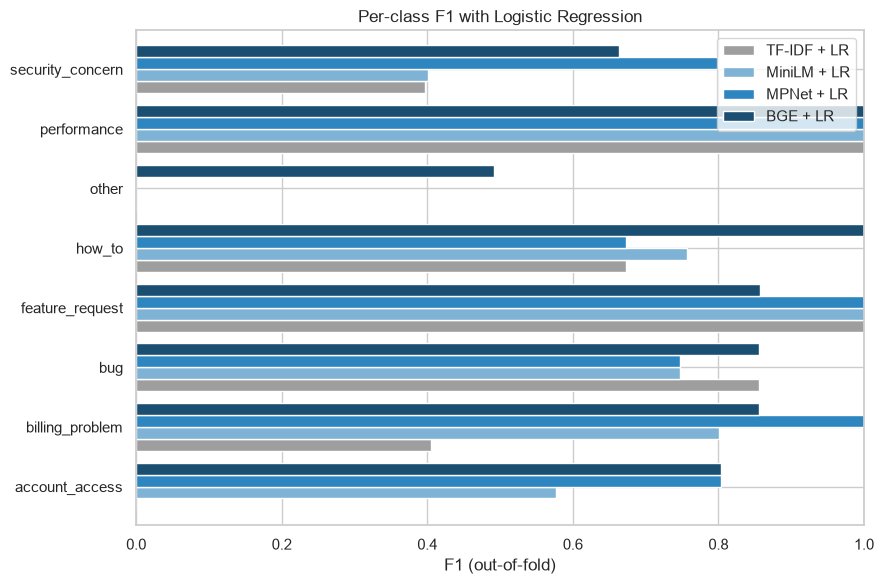

In [9]:
BEST = ("BGE", "Logistic Regression")
OLD = ("TF-IDF", "Logistic Regression")

def oof_pred(key):
    return np.array(classes)[oof[key].argmax(axis=1)]

per_class = pd.DataFrame({
    f"{rep} + LR": pd.Series(f1_score(y, oof_pred((rep, "Logistic Regression")), labels=classes, average=None), index=classes)
    for rep in REPS
})
per_class.loc["macro F1"] = per_class.mean()
display(per_class)

per_class.drop("macro F1").plot.barh(figsize=(9, 6), width=0.8, color=["#9e9e9e", "#7fb3d5", "#2e86c1", "#1b4f72"])
plt.xlim(0, 1); plt.xlabel("F1 (out-of-fold)"); plt.title("Per-class F1 with Logistic Regression")
plt.tight_layout(); plt.savefig(FIG / "26_embedding_per_class.png"); plt.show()

- The two classes TF-IDF **completely missed** improve the most: **account_access 0.00 to 0.80** and **other 0.00 to 0.49**.
- billing_problem goes from 0.41 to 0.86, how_to from 0.67 to 1.00, security_concern from 0.40 to 0.66.
- No single model wins every class. MPNet is better on security_concern (0.80) and billing_problem (1.00), and BGE is better on how_to and other.
- feature_request drops from 1.00 to 0.86. Its recall is still 100%, but one security sentence about "data encryption and compliance" is now predicted as a feature request (see 6.3).
- `other` remains the hardest class. Its sentences are vague by design ("Something seems off…"), so their meaning really does overlap with other categories.

### 6.2 Confusion matrix (BGE + LR, out-of-fold)

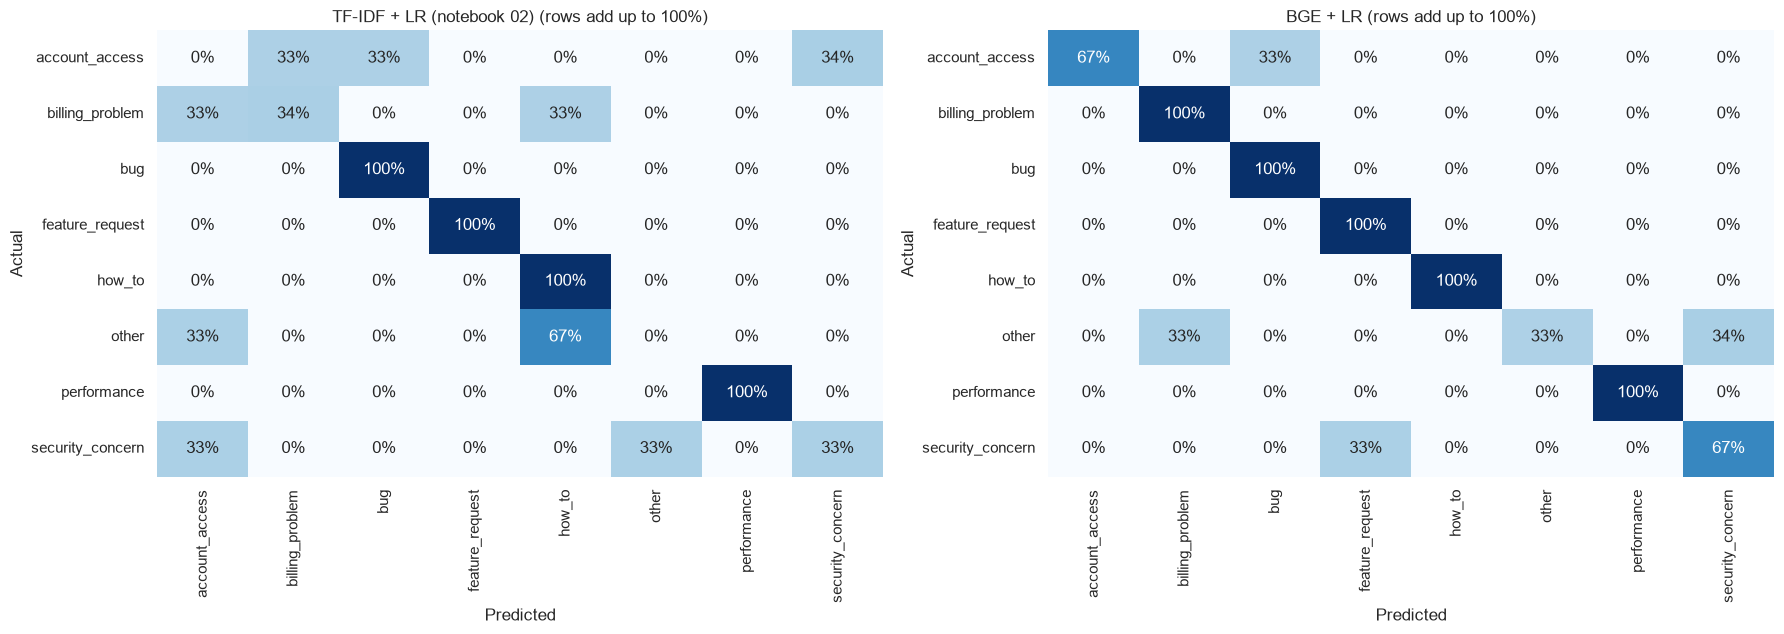

                  precision    recall  f1-score   support

  account_access      1.000     0.671     0.803      2522
 billing_problem      0.748     1.000     0.856      2476
             bug      0.749     1.000     0.856      2470
 feature_request      0.750     1.000     0.857      2497
          how_to      1.000     1.000     1.000      2548
           other      1.000     0.325     0.491      2492
     performance      1.000     1.000     1.000      2503
security_concern      0.662     0.666     0.664      2492

        accuracy                          0.833     20000
       macro avg      0.864     0.833     0.816     20000
    weighted avg      0.864     0.833     0.817     20000



In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, key, title in [(axes[0], OLD, "TF-IDF + LR (notebook 02)"), (axes[1], BEST, "BGE + LR")]:
    cm = confusion_matrix(y, oof_pred(key), labels=classes, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".0%", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set_title(title + " (rows add up to 100%)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(FIG / "27_embedding_confusion.png"); plt.show()

print(classification_report(y, oof_pred(BEST), digits=3))

### 6.3 Which sentences changed?

Every unique message with its out-of-fold prediction under both models, showing only the ones where at least one model is wrong.

In [11]:
first_ticket = pd.Series(np.arange(len(X))).groupby(msg_id).first()       # one ticket per message
cmp = pd.DataFrame({
    "message": messages[TEXT], "true": msg_label, "tickets": np.bincount(msg_id),
    "TF-IDF + LR": oof_pred(OLD)[first_ticket.values],
    "BGE + LR": oof_pred(BEST)[first_ticket.values],
    "BGE confidence": oof[BEST][first_ticket.values].max(axis=1),
})
cmp["TF-IDF ok"] = cmp["TF-IDF + LR"] == cmp["true"]
cmp["BGE ok"] = cmp["BGE + LR"] == cmp["true"]
print(f"Messages right with TF-IDF: {cmp['TF-IDF ok'].sum()}/96 | right with BGE: {cmp['BGE ok'].sum()}/96")
print(f"Fixed by BGE: {(~cmp['TF-IDF ok'] & cmp['BGE ok']).sum()} | broken by BGE: {(cmp['TF-IDF ok'] & ~cmp['BGE ok']).sum()}")
cmp[~cmp["TF-IDF ok"] | ~cmp["BGE ok"]].sort_values(["BGE ok", "true"]).drop(columns=["TF-IDF ok", "BGE ok"])

Messages right with TF-IDF: 86/96 | right with BGE: 92/96
Fixed by BGE: 6 | broken by BGE: 0


,message,true,tickets,TF-IDF + LR,BGE + LR,BGE confidence
11,My 2FA code is not working when I try to sign in.,account_access,829,bug,bug,0.731
0,I have a general question about my account.,other,833,account_access,billing_problem,0.263
10,"Something seems off, can you please check my workspace?",other,848,how_to,security_concern,0.311
38,We need details about your data encryption and compliance.,security_concern,832,other,feature_request,0.576
7,My account was locked after multiple failed login attempts.,account_access,863,security_concern,account_access,0.721
22,I cannot log in; the system says my password is incorrect.,account_access,830,billing_problem,account_access,0.682
13,My invoice amount is incorrect compared to the plan I selected.,billing_problem,814,account_access,billing_problem,0.838
16,I was charged twice for my subscription this month.,billing_problem,821,how_to,billing_problem,0.671
1,I need help but I'm not sure which category this fits in.,other,811,how_to,other,0.790
3,I noticed a suspicious login on my account.,security_concern,829,account_access,security_concern,0.570


- BGE **fixes 6 of the 10 messages** TF-IDF got wrong and **breaks none**.
- Fixed: both notebook 02 examples ("account was locked…" now goes to account_access, "not sure which category…" now goes to other), plus "I was charged twice…", which TF-IDF had sent to how_to.
- Still wrong (4 messages):
  - "My 2FA code is not working when I try to sign in" goes to bug (73% confidence). That is an understandable mistake, since "not working" sounds like a bug.
  - Two vague `other` sentences, at very low confidence (26% and 31%), so they would go to manual review.
  - "We need details about your data encryption and compliance" goes to feature_request (58%), also below the review threshold.
- So **3 of the 4 remaining mistakes would be caught by the manual-review rule**.
- Why is ticket-level F1 (0.82) lower than 92/96 messages would suggest? The hard messages are in the small classes, where each message stands for ~830 tickets, so every wrong message costs a lot of tickets.

### 6.4 Does the confidence rule still work?

Same rule as notebook 02: below 60% confidence the ticket goes to manual review.

In [12]:
rule = []
for key in [OLD, BEST]:
    conf = oof[key].max(axis=1)
    correct = oof_pred(key) == y.values
    review = conf < config.CONFIDENCE_THRESHOLD
    rule.append({"model": f"{key[0]} + LR", "sent to review": review.mean(),
                 "auto-routed accuracy": correct[~review].mean(), "reviewed accuracy": correct[review].mean(),
                 "overall accuracy": correct.mean()})
pd.DataFrame(rule).set_index("model")

,sent to review,auto-routed accuracy,reviewed accuracy,overall accuracy
model,,,,
TF-IDF + LR,0.457,0.924,0.182,0.585
BGE + LR,0.167,0.950,0.248,0.833


- **The share of tickets sent to manual review drops from 46% to 17%**, cutting the manual triage workload by almost two thirds.
- Auto-routed tickets are right **95%** of the time (vs 92% with TF-IDF).
- Overall accuracy goes from **58% to 83%**.
- Reviewed tickets are mostly wrong (25% accuracy), which is what we want: the rule is catching the mistakes.

## 7. Save results

In [13]:
holdout.to_csv(config.PROCESSED / "embedding_holdout_comparison.csv", index=False)
cv_scores.to_csv(config.PROCESSED / "embedding_cv_scores.csv", index=False)
per_class.to_csv(config.PROCESSED / "embedding_per_class_f1.csv")
pd.DataFrame(rule).to_csv(config.PROCESSED / "embedding_confidence_rule.csv", index=False)
cmp.to_csv(config.PROCESSED / "embedding_message_changes.csv", index=False)
best_report = pd.DataFrame(classification_report(y, oof_pred(BEST), output_dict=True, zero_division=0)).T
best_report.loc[classes, "roc_auc"] = [roc_auc_score((y == c).astype(int), oof[BEST][:, i]) for i, c in enumerate(classes)]
best_report.to_csv(config.PROCESSED / "embedding_class_report.csv")
best_scores = scores_for(y, oof[BEST])
json.dump({"model": "BGE (BAAI/bge-base-en-v1.5) embeddings + Logistic Regression",
           "evaluation": "grouped 5-fold cross-validation by message (out-of-fold)",
           **{k: float(v) for k, v in best_scores.items()},
           "cv_f1_macro_mean": float(cv_scores.query("representation == 'BGE' and classifier == 'Logistic Regression'")["f1_macro_mean"].item()),
           "messages_right_tfidf": int(cmp["TF-IDF ok"].sum()), "messages_right_bge": int(cmp["BGE ok"].sum()),
           "messages_fixed": int((~cmp["TF-IDF ok"] & cmp["BGE ok"]).sum()), "messages_broken": int((cmp["TF-IDF ok"] & ~cmp["BGE ok"]).sum())},
          open(config.PROCESSED / "embedding_metrics.json", "w"), indent=2)

# final BGE + LR model, trained on all 96 messages (weighted by tickets). To use it, encode new text with the same BGE model.
train_ids, weights = np.unique(msg_id, return_counts=True)
final = LogisticRegression(max_iter=3000, C=1.0).fit(embeddings["BGE"][train_ids], msg_label[train_ids], sample_weight=weights)
joblib.dump({"encoder": EMBEDDERS["BGE"], "classifier": final}, config.MODELS / "bge_logreg.joblib")
print("Saved embedding_*.csv, embedding_metrics.json and models/bge_logreg.joblib")

encoder = SentenceTransformer(EMBEDDERS["BGE"])
for text in ["I was charged twice for my subscription this month.",
             "I can't get into my account, it says my password is wrong.",
             "The coffee machine on the third floor is broken."]:
    p = final.predict_proba(encoder.encode([text], normalize_embeddings=True, show_progress_bar=False))[0]
    top = np.argsort(-p)[:2]
    print(f"{text:62s} -> {final.classes_[top[0]]} ({p[top[0]]:.2f}), runner-up {final.classes_[top[1]]} ({p[top[1]]:.2f})")

Saved embedding_*.csv, embedding_metrics.json and models/bge_logreg.joblib


I was charged twice for my subscription this month.            -> billing_problem (0.99), runner-up security_concern (0.00)
I can't get into my account, it says my password is wrong.     -> account_access (0.98), runner-up other (0.01)
The coffee machine on the third floor is broken.               -> other (0.30), runner-up performance (0.27)


## Summary

| Item | TF-IDF + LR (notebook 02) | BGE + LR (this notebook) |
|---|---|---|
| Features | word / word-pair counts (~400) | pre-trained sentence embedding (768) |
| Grouped CV macro F1 (mean ± std) | 0.59 ± 0.05 | **0.81 ± 0.10** |
| Out-of-fold macro F1 / accuracy | 0.54 / 0.58 | **0.82 / 0.83** |
| Out-of-fold macro ROC-AUC | 0.86 | **0.99** |
| account_access / other F1 | 0.00 / 0.00 | **0.80 / 0.49** |
| Sent to manual review | 46% | **17%** |
| Auto-routed accuracy | 92% | **95%** |

**Ranking of representations (best classifier each, grouped CV):** BGE 0.82 > MPNet 0.79 > MiniLM 0.71 > TF-IDF 0.59.
**Ranking of classifiers on embeddings:** Linear SVM ≈ Logistic Regression > kNN > Random Forest.

**Trade-offs**
- Embeddings need `sentence-transformers` (PyTorch) and a ~440 MB model. TF-IDF + LR is tiny and instant.
- SHAP values on embedding dimensions don't map to words. Word-level SHAP for this model is computed in notebook 03b (each word deleted and the sentence re-embedded), which is slower than the instant TF-IDF formula.
- With only 96 sentences, all these scores come from very little data. Real tickets with more varied wording are needed to confirm the ranking.

**Saved:** `data/processed/embedding_holdout_comparison.csv`, `embedding_cv_scores.csv`, `embedding_per_class_f1.csv`, `embedding_class_report.csv`, `embedding_confidence_rule.csv`, `embedding_message_changes.csv`, `embedding_metrics.json`, figures `25`–`27`, and `models/bge_logreg.joblib` (BGE + LR trained on all messages). The dashboard still uses the TF-IDF model from notebook 02.